# 04 · Phân cụm (Clustering) + ARI

## Mục tiêu
Áp dụng **phân cụm không dấu (unsupervised)** trên 22 feature chuẩn hoá bằng **K-Means** và
**DBSCAN**, sau đó **đánh giá bằng Adjusted Rand Index (ARI)** so với nhãn thật `status`.
Mục đích: kiểm tra xem cấu trúc tự nhiên của dữ liệu có khớp với chia 0/1 (khỏe / Parkinson) không.

## Yêu cầu bài tập liên quan
- Phân cụm + chọn K (M06-T1), ARI (M06-T2).

## Phạm vi của notebook này
- **M06** — K-Means, DBSCAN, đánh giá ARI, nhận xét cụm & nhiễu.

## KHÔNG thuộc phạm vi
- Không viết sẵn kết quả phân cụm / ARI giả. Không tổng hợp báo cáo (→ notebook 05).


## Phân công (theo `TASK_ASSIGNMENTS.md`)

| Nhiệm vụ | Phụ trách | Reviewer |
|---|---|---|
| M06-T1 Phân cụm (KMeans, chọn K) | M06 | M05 |
| M06-T2 ARI (so cluster với `status`) | M06 | M01 (gate) |

**Tên / MSSV thành viên:** M06 = **Nguyễn Hoàng Bách** (MSSV `056205005522`) (xem `TEAM.md`).


## Điều kiện bắt đầu

- **Đầu vào:** `data/processed/parkinsons_v1.csv` (195 mẫu, 22 đặc trưng âm học + `status`; theo `schema_v1.md` file canonical **chưa chuẩn hoá**) — việc chuẩn hoá Z-score được thực hiện ngay trong notebook này bằng `StandardScaler` (quy trình tham chiếu M04-T1). `y = status` chỉ dùng cho đánh giá.
- **Phụ thuộc:** M04-T1 đã `Done` (PR #7); đầu vào canonical + `Xs` sẵn sàng, không còn Blocked.


In [4]:
# M06-T1: nạp dữ liệu canonical (đọc local, không tải từ mạng) + tách nhãn
import datetime, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
SEED = 42

def find_root(start=None):
    """Đi ngược lên thư mục cha cho tới khi thấy data/processed/parkinsons_v1.csv hoặc .git"""
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "data" / "processed" / "parkinsons_v1.csv").exists() or (cand / ".git").exists():
            return cand
    return p

ROOT = find_root()
CSV_PATH = ROOT / "data" / "processed" / "parkinsons_v1.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert CSV_PATH.exists(), f"Không tìm thấy dữ liệu chuẩn tại: {CSV_PATH}"
df = pd.read_csv(CSV_PATH)
NGUON = "data/processed/parkinsons_v1.csv"

# Tách định danh và nhãn mục tiêu
if "name" in df.columns:
    df = df.drop(columns=["name"])
y = df["status"].copy()
X = df.drop(columns=["status"]).copy()
print(f"ROOT = {ROOT}")
print(f"df: {df.shape} | nhãn tách riêng: y = status")

ROOT = C:\Users\Admin\Documents\Nhom_3_KhaiThacDuLieu_Parkinsons
df: (195, 23) | nhãn tách riêng: y = status


## Bước 1 · Chuẩn bị đặc trưng đầu vào (QUY TẮC: loại nhãn)
**Mục tiêu:** matrix đầu vào của K-Means / DBSCAN **CHỈ gồm 22 feature**, **KHÔNG** chứa `status` hay `name`.
**Quy tắc (bắt buộc):** phân cụm là **unsupervised** — **cấm** đưa cột nhãn `status` vào input.
`y = status` chỉ được dùng **ở bước đánh giá ARI** (so sánh), không phải đầu vào.
**Câu hỏi tự kiểm:** `X.columns` có `status` không? (Phải **KHÔNG**.) Có đủ 22 feature không?


In [5]:
# M06-T1: xác nhận X không chứa nhãn / định danh
assert "status" not in X.columns and "name" not in X.columns, "LỖI: nhãn/name lẫn vào input phân cụm!"
assert X.shape == (195, 22), f"Kích thước X không khớp (195, 22), nhận được: {X.shape}"
assert X.isna().sum().sum() == 0, "Dữ liệu vẫn còn giá trị khuyết (NaN)!"

print(f"Nguồn dữ liệu : {NGUON}")
print(f"Kích thước X  : {X.shape} | Phân bố nhãn status: {y.value_counts().to_dict()}")

Nguồn dữ liệu : data/processed/parkinsons_v1.csv
Kích thước X  : (195, 22) | Phân bố nhãn status: {1: 147, 0: 48}


## Bước 2 · Xử lý / chuẩn hoá dữ liệu khi cần
**Mục tiêu:** K-Means & DBSCAN nhạy với khoảng cách → phải đưa 22 đặc trưng về cùng thang đo.
**Quyết định:** file canonical chưa chuẩn hoá nên dùng `StandardScaler` (Z-score, μ=0, σ=1) trên X; `y` không được dùng ở bước này. Quyết định được ghi lại trong cột `data_source`/`seed` của `results/m06_cluster_ari.csv`.


In [6]:
# M06-T1: chuẩn hoá Z-score (unsupervised: không dùng y)
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
print(f"Xs: {Xs.shape} | mean≈{Xs.mean():.3f} | std≈{Xs.std():.3f}")

Xs: (195, 22) | mean≈0.000 | std≈1.000


## Bước 3 · Thực hiện K-Means
**Mục tiêu:** chạy K-Means với K = 2…10 và **chọn K** bằng **Silhouette cực đại** (đối chiếu thêm đường cong Elbow của Inertia).
**Lưu ý:** `random_state=42`, `n_init=10`; K=2 là mốc so với 2 lớp. Ở bước này **chưa dùng nhãn `status`** — ARI chỉ tính ở Bước 5.


 K  inertia  silhouette                        kich_thuoc_cum
 2   2817.2      0.4373                             [165, 30]
 3   2076.2      0.2763                         [106, 77, 12]
 4   1822.4      0.2358                       [91, 77, 23, 4]
 5   1595.5      0.2048                   [73, 64, 32, 22, 4]
 6   1442.0      0.2138               [60, 51, 30, 28, 22, 4]
 7   1319.8      0.2094            [54, 51, 31, 24, 23, 8, 4]
 8   1230.5      0.2201       [53, 35, 32, 23, 23, 15, 10, 4]
 9   1157.0      0.2265     [52, 39, 25, 24, 21, 13, 9, 8, 4]
10   1110.7      0.1896 [38, 35, 26, 23, 22, 18, 12, 9, 8, 4]

=> K chọn (Silhouette cực đại) = 2

Top 5 đặc trưng chênh lệch (cụm nhỏ - cụm lớn, đơn vị z-score):
Shimmer:APQ5        2.18
MDVP:Shimmer        2.17
MDVP:Shimmer(dB)    2.15
Shimmer:APQ3        2.13
Shimmer:DDA         2.13


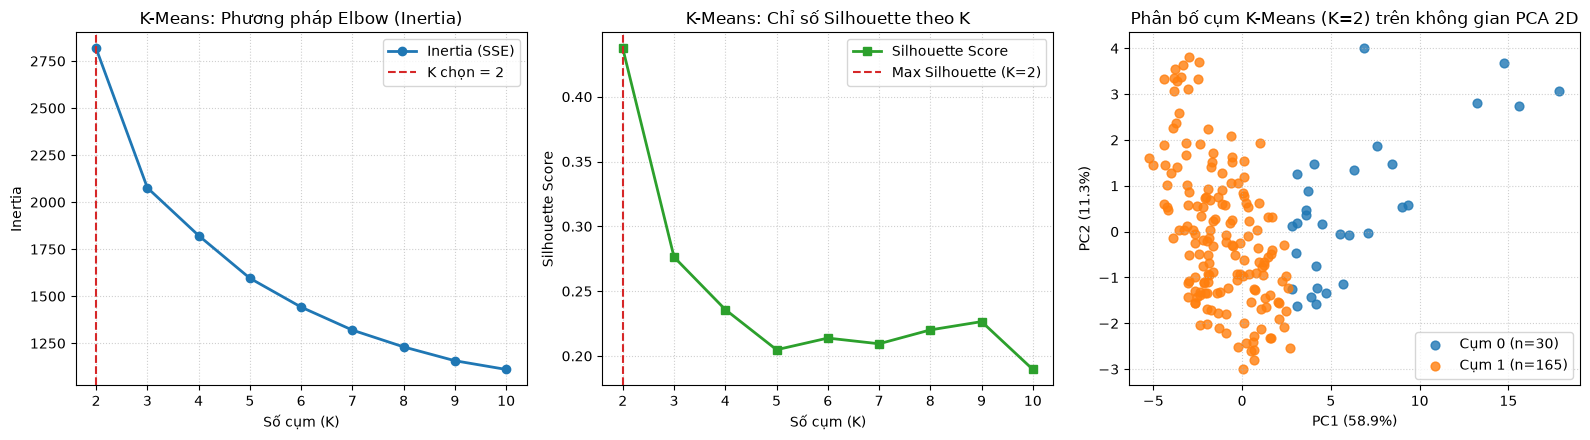

In [7]:
# M06-T1: K-Means K = 2..10, chọn K theo Silhouette (CHƯA dùng nhãn status)
K_RANGE = list(range(2, 11))
labels_km, km_rows = {}, []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    labels_km[k] = km.labels_
    km_rows.append({
        "K": k,
        "inertia": round(float(km.inertia_), 1),
        "silhouette": round(float(silhouette_score(Xs, km.labels_)), 4),
        "kich_thuoc_cum": str(sorted(np.bincount(km.labels_).tolist(), reverse=True)),
    })

km_table = pd.DataFrame(km_rows)
K_CHON = int(km_table.loc[km_table["silhouette"].idxmax(), "K"])
print(km_table.to_string(index=False))
print(f"\n=> K chọn (Silhouette cực đại) = {K_CHON}")

# Đặc trưng khác biệt nhất của cụm nhỏ ở K chọn (chỉ dùng Xs, không dùng y)
lab_best = labels_km[K_CHON]
nho = int(np.argmin(np.bincount(lab_best)))
Xs_df = pd.DataFrame(Xs, columns=X.columns)
chenh = (Xs_df[lab_best == nho].mean() - Xs_df[lab_best != nho].mean()).sort_values(ascending=False)
print("\nTop 5 đặc trưng chênh lệch (cụm nhỏ - cụm lớn, đơn vị z-score):")
print(chenh.head(5).round(2).to_string())

# Hình 1: Elbow, Silhouette, PCA 2D
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(Xs)
var_ratio = pca.explained_variance_ratio_ * 100

fig1, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(km_table["K"], km_table["inertia"], marker="o", color="#1f77b4", linewidth=2, label="Inertia (SSE)")
ax[0].axvline(K_CHON, color="#d62728", linestyle="--", label=f"K chọn = {K_CHON}")
ax[0].set(title="K-Means: Phương pháp Elbow (Inertia)", xlabel="Số cụm (K)", ylabel="Inertia", xticks=K_RANGE)
ax[1].plot(km_table["K"], km_table["silhouette"], marker="s", color="#2ca02c", linewidth=2, label="Silhouette Score")
ax[1].axvline(K_CHON, color="#d62728", linestyle="--", label=f"Max Silhouette (K={K_CHON})")
ax[1].set(title="K-Means: Chỉ số Silhouette theo K", xlabel="Số cụm (K)", ylabel="Silhouette Score", xticks=K_RANGE)
for cid, cname, color in [(0, "Cụm 0", "#1f77b4"), (1, "Cụm 1", "#ff7f0e")]:
    idx = labels_km[K_CHON] == cid
    ax[2].scatter(X_pca[idx, 0], X_pca[idx, 1], label=f"{cname} (n={idx.sum()})", alpha=0.8, s=40, color=color)
ax[2].set(title=f"Phân bố cụm K-Means (K={K_CHON}) trên không gian PCA 2D",
          xlabel=f"PC1 ({var_ratio[0]:.1f}%)", ylabel=f"PC2 ({var_ratio[1]:.1f}%)")
for a in ax:
    a.grid(True, linestyle=":", alpha=0.6); a.legend()
plt.tight_layout()
fig1_path = FIGURES_DIR / "m06_kmeans_selection.png"
fig1.savefig(fig1_path, dpi=150, bbox_inches="tight")
plt.show()

## Bước 4 · Thực hiện DBSCAN
**Mục tiêu:** thử DBSCAN (hợp khi có nhiễu / cấu trúc không lồi).
**Cách chọn tham số:** `min_samples = 5`, `eps` lấy từ **điểm khuỷu tay (knee)** của đường cong k-distance (≈ 3.37), đồng thời khảo sát lưới `min_samples ∈ {3, 5, 10}` × `eps ∈ {1.5…5.0, knee}`. Điểm nhiễu có `label = -1`.


In [8]:
# M06-T1: DBSCAN — chọn eps bằng knee của k-distance + khảo sát lưới (CHƯA dùng nhãn status)
def knee_eps(Xm, min_samples):
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xm)
    dists, _ = nn.kneighbors(Xm)
    kd = np.sort(dists[:, -1])
    t = np.arange(len(kd)) / (len(kd) - 1)
    v = (kd - kd.min()) / (kd.max() - kd.min())
    return kd, float(kd[np.argmax(t - v)])

MS_LIST = [3, 5, 10]
kdist, knee = {}, {}
for ms in MS_LIST:
    kdist[ms], knee[ms] = knee_eps(Xs, ms)

MIN_SAMPLES = 5
EPS = round(knee[MIN_SAMPLES], 2)
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Xs)
n_cum_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_nhieu = int((labels_db == -1).sum())
mask_core = labels_db != -1
sil_db = round(float(silhouette_score(Xs[mask_core], labels_db[mask_core])), 4) if n_cum_db >= 2 else float("nan")

EPS_GRID = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
grid_rows, labels_grid = [], {}
for ms in MS_LIST:
    for eps_val in sorted(set(EPS_GRID + [round(knee[ms], 2)])):
        lbl = DBSCAN(eps=eps_val, min_samples=ms).fit_predict(Xs)
        labels_grid[(ms, eps_val)] = lbl
        n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
        sil_c = round(float(silhouette_score(Xs[lbl != -1], lbl[lbl != -1])), 4) if n_c >= 2 else float("nan")
        grid_rows.append({"min_samples": ms, "eps": eps_val, "is_knee": eps_val == round(knee[ms], 2),
                          "so_cum": n_c, "so_nhieu": int((lbl == -1).sum()), "silhouette_non_noise": sil_c})
grid_df = pd.DataFrame(grid_rows)

print(f"Knee raw (min_samples={MIN_SAMPLES}) = {knee[MIN_SAMPLES]:.4f} -> eps = {EPS}")
print(f"Số cụm = {n_cum_db} | Nhiễu (-1) = {n_nhieu} | Kích thước cụm: {np.bincount(labels_db[mask_core]).tolist()}")
print("\nLưới tham số (chưa có ARI):")
print(grid_df.to_string(index=False))

Knee raw (min_samples=5) = 3.3741 -> eps = 3.37
Số cụm = 1 | Nhiễu (-1) = 12 | Kích thước cụm: [183]

Lưới tham số (chưa có ARI):
 min_samples  eps  is_knee  so_cum  so_nhieu  silhouette_non_noise
           3 1.50    False      17        97                0.3259
           3 2.00    False       4        52               -0.0213
           3 2.50    False       3        24                0.3206
           3 2.80     True       2        15                0.4799
           3 3.00    False       2        15                0.4799
           3 3.50    False       2         5                0.4413
           3 4.00    False       2         5                0.4413
           3 5.00    False       1         4                   NaN
           5 1.50    False       5       149                0.3833
           5 2.00    False       2        74                0.3095
           5 2.50    False       1        35                   NaN
           5 3.00    False       1        20                   NaN

## Bước 5 · Đánh giá bằng ARI (dùng nhãn THẬT chỉ ở bước này)
**Mục tiêu:** **Adjusted Rand Index (ARI)** so nhãn cluster với `status` thật.
**Lưu ý:** ARI = 1 khi khớp hoàn toàn, 0 khi ngẫu nhiên, <0 khi kém hơn ngẫu nhiên.
Chạy ARI **cho cả KMeans (nhiều K) và DBSCAN**. Nhãn `status` chỉ xuất hiện ở **đây**.


=== K-MEANS (K = 2..10) ===
 K  inertia  silhouette                        kich_thuoc_cum     ARI chon
 2   2817.2      0.4373                             [165, 30] -0.0978  <--
 3   2076.2      0.2763                         [106, 77, 12]  0.0582     
 4   1822.4      0.2358                       [91, 77, 23, 4]  0.0583     
 5   1595.5      0.2048                   [73, 64, 32, 22, 4]  0.1000     
 6   1442.0      0.2138               [60, 51, 30, 28, 22, 4]  0.1058     
 7   1319.8      0.2094            [54, 51, 31, 24, 23, 8, 4]  0.0882     
 8   1230.5      0.2201       [53, 35, 32, 23, 23, 15, 10, 4]  0.0313     
 9   1157.0      0.2265     [52, 39, 25, 24, 21, 13, 9, 8, 4]  0.0574     
10   1110.7      0.1896 [38, 35, 26, 23, 22, 18, 12, 9, 8, 4]  0.0481     

=== DBSCAN (eps=3.37, min_samples=5) ===
Số cụm = 1 | Nhiễu = 12 | ARI = -0.0639
Khoảng ARI trên lưới DBSCAN: [-0.0744, 0.1625]


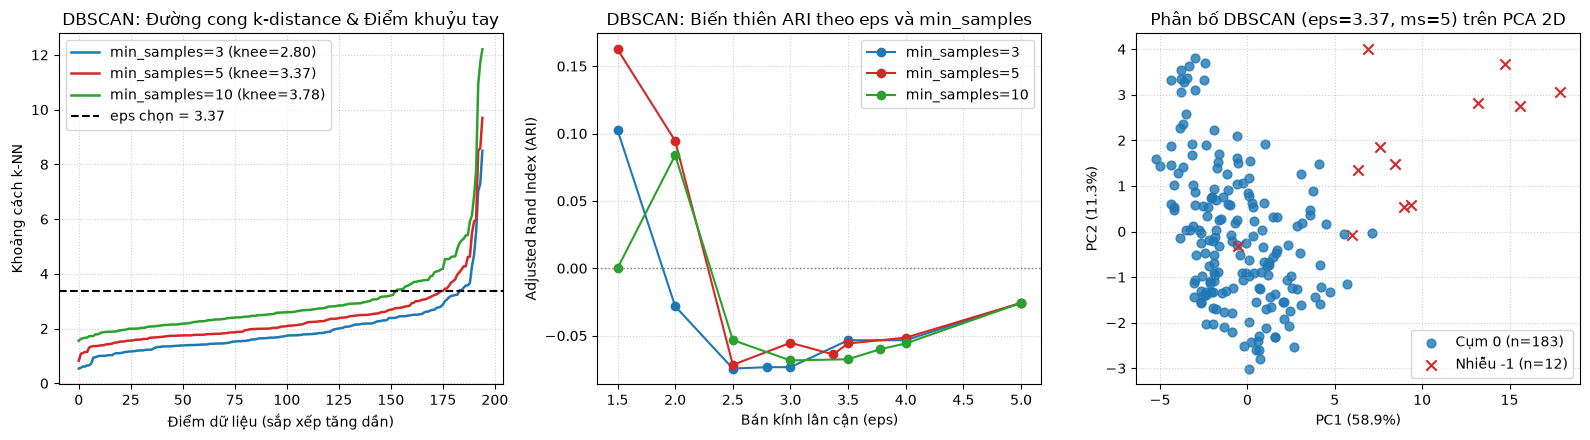

Đã lưu:
 - results\m06_cluster_ari.csv
 - results\m06_dbscan_grid.csv
 - results\figures\m06_kmeans_selection.png
 - results\figures\m06_dbscan_analysis.png


In [9]:
# M06-T2: ARI — dùng nhãn THẬT y = status CHỈ ở bước này, rồi xuất artifact
km_table["ARI"] = [round(float(adjusted_rand_score(y, labels_km[k])), 4) for k in km_table["K"]]
km_table["chon"] = np.where(km_table["K"] == K_CHON, "<--", "")
ari_db = round(float(adjusted_rand_score(y, labels_db)), 4)
grid_df["ARI"] = [round(float(adjusted_rand_score(y, labels_grid[(r.min_samples, r.eps)])), 4)
                  for r in grid_df.itertuples()]

print("=== K-MEANS (K = 2..10) ===")
print(km_table.to_string(index=False))
print(f"\n=== DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES}) ===")
print(f"Số cụm = {n_cum_db} | Nhiễu = {n_nhieu} | ARI = {ari_db}")
print(f"Khoảng ARI trên lưới DBSCAN: [{grid_df['ARI'].min():.4f}, {grid_df['ARI'].max():.4f}]")

# Hình 2: DBSCAN
fig2, ax = plt.subplots(1, 3, figsize=(16, 4.5))
cols = ["#1f77b4", "#d62728", "#2ca02c"]
for ms, col in zip(MS_LIST, cols):
    ax[0].plot(kdist[ms], label=f"min_samples={ms} (knee={knee[ms]:.2f})", color=col, linewidth=1.8)
ax[0].axhline(EPS, color="black", linestyle="--", label=f"eps chọn = {EPS}")
ax[0].set(title="DBSCAN: Đường cong k-distance & Điểm khuỷu tay",
          xlabel="Điểm dữ liệu (sắp xếp tăng dần)", ylabel="Khoảng cách k-NN")
for ms, col in zip(MS_LIST, cols):
    sub = grid_df[grid_df["min_samples"] == ms].sort_values("eps")
    ax[1].plot(sub["eps"], sub["ARI"], marker="o", label=f"min_samples={ms}", color=col)
ax[1].axhline(0, color="gray", linestyle=":", linewidth=1)
ax[1].set(title="DBSCAN: Biến thiên ARI theo eps và min_samples",
          xlabel="Bán kính lân cận (eps)", ylabel="Adjusted Rand Index (ARI)")
inl, noi = labels_db != -1, labels_db == -1
ax[2].scatter(X_pca[inl, 0], X_pca[inl, 1], c="#1f77b4", label=f"Cụm 0 (n={inl.sum()})", alpha=0.8, s=40)
ax[2].scatter(X_pca[noi, 0], X_pca[noi, 1], c="#d62728", marker="x", label=f"Nhiễu -1 (n={noi.sum()})", s=55)
ax[2].set(title=f"Phân bố DBSCAN (eps={EPS}, ms={MIN_SAMPLES}) trên PCA 2D",
          xlabel=f"PC1 ({var_ratio[0]:.1f}%)", ylabel=f"PC2 ({var_ratio[1]:.1f}%)")
for a in ax:
    a.grid(True, linestyle=":", alpha=0.6); a.legend()
plt.tight_layout()
fig2_path = FIGURES_DIR / "m06_dbscan_analysis.png"
fig2.savefig(fig2_path, dpi=150, bbox_inches="tight")
plt.show()

# Xuất artifact vào results/ (đúng quy ước results/<mã>.csv, results/figures/)
db_row = pd.DataFrame([{"K": f"DBSCAN(eps={EPS},ms={MIN_SAMPLES})", "inertia": np.nan, "silhouette": sil_db,
                        "kich_thuoc_cum": f"[{int(inl.sum())}] (nhiễu: {n_nhieu})", "ARI": ari_db, "chon": "DBSCAN"}])
export_ari_df = pd.concat([km_table, db_row], ignore_index=True)
export_ari_df["data_source"] = NGUON
export_ari_df["seed"] = SEED
export_ari_df["date"] = datetime.date.today().isoformat()
export_ari_df["python_libs"] = f"sklearn={sklearn.__version__};pandas={pd.__version__};numpy={np.__version__}"

ari_csv_path = RESULTS_DIR / "m06_cluster_ari.csv"
grid_csv_path = RESULTS_DIR / "m06_dbscan_grid.csv"
export_ari_df.to_csv(ari_csv_path, index=False, encoding="utf-8-sig")
grid_df[["min_samples", "eps", "is_knee", "so_cum", "so_nhieu", "silhouette_non_noise", "ARI"]].to_csv(
    grid_csv_path, index=False, encoding="utf-8-sig")
print("Đã lưu:")
for p in (ari_csv_path, grid_csv_path, fig1_path, fig2_path):
    print(" -", p.relative_to(ROOT))

## Kết quả & nhận xét

**Bảng so sánh (số liệu từ lần chạy thật, seed = 42):**

| Phương pháp | Tham số (K hoặc eps/min_samples) | #cụm (+nhiễu) | ARI |
|---|---|---|---|
| K-Means (K=2) — K được chọn | K=2, Silhouette = 0.4373 | 2 cụm `[165, 30]` | -0.0978 |
| K-Means (K=6) — ARI cao nhất | K=6, Silhouette = 0.2138 | 6 cụm `[60, 51, 30, 28, 22, 4]` | 0.1058 |
| DBSCAN | eps=3.37, min_samples=5 | 1 cụm (183 điểm) + 12 nhiễu | -0.0639 |

**Trả lời câu hỏi gợi ý:**
1. K-Means chọn **K=2** (Silhouette cực đại 0.4373; Inertia giảm đều, không có điểm gập rõ — Elbow chỉ đối chiếu). ARI tại K=2 là **-0.0978**, thấp hơn các K khác (tối đa 0.1058 tại K=6) nhưng mọi giá trị đều xấp xỉ 0 ⇒ không K nào khớp với `status`.
2. DBSCAN (eps=3.37, min_samples=5) chỉ tạo **1 cụm chính (183 điểm)** và **12 điểm nhiễu**; các điểm nhiễu nằm xa phần còn lại (PC1 lớn) trên PCA 2D. ARI = **-0.0639**. Trên toàn lưới, ARI ∈ [-0.0744, 0.1625] (giá trị cao nhất tại eps=1.5, min_samples=5 nhưng khi đó 149/195 điểm bị coi là nhiễu nên không có ý nghĩa).
3. ARI ≈ 0 hoặc âm ⇒ cấu trúc tự nhiên (hình học/mật độ) **không khớp** phân chia khỏe/Parkinson. K=2 chủ yếu tách một nhóm nhỏ 30 mẫu có độ lệch lớn, không phải ranh giới bệnh lý. Cần mô hình **có giám sát** (M05) để phân loại.


## Checklist nghiệm thu & bàn giao (trạng thái ban đầu: `Todo`)

### Hoàn thành
- [x] Đầu vào K-Means / DBSCAN **không** chứa `status`/`name` (đã `assert`).
- [x] Đã chạy K-Means với **nhiều K** + chọn K (ghi silhouette/elbow).
- [x] Đã chạy DBSCAN + chọn `eps`/`min_samples` (ghi số nhiễu -1).
- [x] Đã tính **ARI** cho cả K-Means & DBSCAN, so với `status`.

### Kiểm tra
- [x] ARI / số cụm là **kết quả thật** (không bịa), lưu figure/kết quả vào `results/`.
- [x] Nhãn `status` chỉ dùng ở bước ARI (đã kiểm tra code).

### Bàn giao
- [x] Đã chuyển M06-T1, M06-T2 sang `Review` trong `TASK_BOARD.md`.
- [ ] Đã thông báo reviewer (M05 cho phân cụm, M01-gate cho ARI) + góp ý tổng hợp cho M06-T3.

### Vấn đề chưa giải quyết
- [ ] _(ghi nếu có)_


## Tái lập & xử lý Blocked

- **Nguồn dữ liệu:** `data/processed/parkinsons_v1.csv` (canonical, chưa chuẩn hoá; đọc local qua `find_root()`, không tải từ mạng) + `y = status`.
- **Đầu ra:** `results/m06_cluster_ari.csv`, `results/m06_dbscan_grid.csv`, `results/figures/m06_kmeans_selection.png`, `results/figures/m06_dbscan_analysis.png`.
- **Đã ghi lại** trong CSV: seed = 42, K/eps/min_samples, silhouette, ARI, ngày chạy (`date`) và phiên bản thư viện (`python_libs`).
- **Không hardcode** đường dẫn cá nhân.
- **Blocked:** không còn — M04-T1 đã `Done` (PR #7); đầu vào canonical + `Xs` sẵn sàng.
